# Bank Customer Churn Prediction — Class Imbalance Analysis

Predicting customer churn for Beta Bank using Random Forest, class weighting, minority-class upsampling, and F1/ROC-AUC evaluation. The target is `Exited`, and the minimum required test F1 score is **0.59**.

The notebook uses a 60% training, 20% validation, and 20% test split.

## 1. Libraries

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import shuffle

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

## 2. Data loading and exploration

In [27]:
# Load the dataset
data = pd.read_csv('../data/Churn.csv')

# Preview the first rows
display(data.head())

# Check dataset dimensions
print('Dataset dimensions:', data.shape)

# Inspect data types and missing values
data.info()

# Review descriptive statistics
display(data.describe())

# Check missing values
print('\nMissing values by column:')
print(data.isna().sum())

# Check duplicate records
print('\nNumber of duplicate rows:')
print(data.duplicated().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


Dimensões do dataset: (10000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,9091.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,4.997690,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.894723,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,2.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Valores ausentes por coluna:
RowNumber            0
CustomerId           0
Surname              0
CreditScore          0
Geography            0
Gender               0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

Número de registros duplicados:
0


## 3. Data preprocessing

In [28]:
# Fill missing Tenure values with the median
data['Tenure'] = data['Tenure'].fillna(data['Tenure'].median())

# Remove columns not needed for modeling
data = data.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

# One-hot encode categorical features
data_ohe = pd.get_dummies(data, drop_first=True)

# Inspect the transformed dataset
print(data_ohe.head())
print(data_ohe.isna().sum())

   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42     2.0       0.00              1          1   
1          608   41     1.0   83807.86              1          0   
2          502   42     8.0  159660.80              3          1   
3          699   39     1.0       0.00              2          0   
4          850   43     2.0  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Exited  Geography_Germany  \
0               1        101348.88       1                  0   
1               1        112542.58       0                  0   
2               0        113931.57       1                  0   
3               0         93826.63       0                  0   
4               1         79084.10       0                  0   

   Geography_Spain  Gender_Male  
0                0            0  
1                1            0  
2                0            0  
3                0            0  
4                1            

The dataset contains 10,000 customer records. Initial inspection found 909 missing values in `Tenure` and no duplicate rows. Missing tenure values were imputed using the median, while `RowNumber`, `CustomerId`, and `Surname` were excluded as identifiers. `Geography` and `Gender` were encoded using one-hot encoding with `drop_first=True`. After preprocessing, no missing values remained. **Methodological limitation:** tenure imputation was performed before splitting the data, so the median includes validation and test observations. A production-ready pipeline should fit imputation on the training partition only.

## 4. Class balance and dataset splitting

0    0.7963
1    0.2037
Name: Exited, dtype: float64


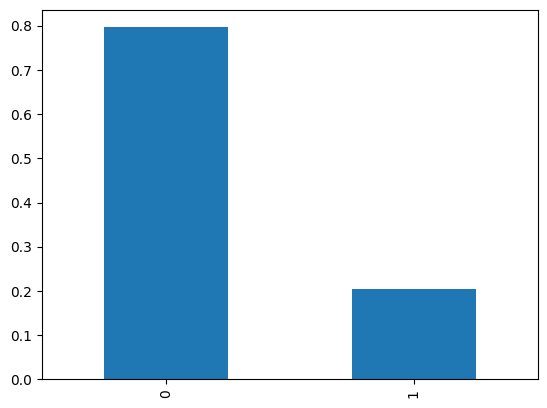

In [29]:
# Inspect class distribution
class_frequency = data_ohe['Exited'].value_counts(normalize=True)

print(class_frequency)

class_frequency.plot(kind='bar')
plt.show()

In [30]:
# Separate features and target
features = data_ohe.drop('Exited', axis=1)
target = data_ohe['Exited']

# Split training data from the remaining observations
features_train, features_valid_test, target_train, target_valid_test = train_test_split(
    features,
    target,
    test_size=0.4,
    random_state=12345
)

# Split the remaining data into validation and test sets
features_valid, features_test, target_valid, target_test = train_test_split(
    features_valid_test,
    target_valid_test,
    test_size=0.5,
    random_state=12345
)

print('Training:', features_train.shape)
print('Validation:', features_valid.shape)
print('Test:', features_test.shape)

Treino: (6000, 11)
Validação: (2000, 11)
Teste: (2000, 11)


In [31]:

# Create copies of the partitions
features_train = features_train.copy()
features_valid = features_valid.copy()
features_test = features_test.copy()

# Select numeric features
numeric = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'EstimatedSalary'
]

# Scale numeric features
scaler = StandardScaler()
scaler.fit(features_train[numeric])

features_train[numeric] = scaler.transform(features_train[numeric])
features_valid[numeric] = scaler.transform(features_valid[numeric])
features_test[numeric] = scaler.transform(features_test[numeric])

print(features_train.head())

      CreditScore       Age    Tenure   Balance  NumOfProducts  HasCrCard  \
7479    -0.886751 -0.373192  1.082277  1.232271      -0.891560          1   
3411     0.608663 -0.183385  1.082277  0.600563      -0.891560          0   
6027     2.052152  0.480939 -0.737696  1.027098       0.830152          0   
1247    -1.457915 -1.417129  0.354288 -1.233163       0.830152          1   
3716     0.130961 -1.132419 -1.101690  1.140475      -0.891560          0   

      IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
7479               0        -0.187705                  0                1   
3411               0        -0.333945                  0                0   
6027               1         1.503095                  1                0   
1247               0        -1.071061                  0                0   
3716               0         1.524268                  1                0   

      Gender_Male  
7479            1  
3411            0  
6027          

## 5. Baseline Random Forest

In [32]:
# Train a baseline model without class imbalance treatment
model = RandomForestClassifier(
    random_state=12345,
    n_estimators=100
)

model.fit(features_train, target_train)

# Generate validation predictions
predicted_valid = model.predict(features_valid)

# Calculate F1 score
f1 = f1_score(target_valid, predicted_valid)

print('F1:', f1)

F1: 0.5769805680119582


In [33]:
# Predict positive-class probabilities
probabilities_valid = model.predict_proba(features_valid)
probabilities_one_valid = probabilities_valid[:, 1]

# Calculate ROC-AUC
auc_roc = roc_auc_score(target_valid, probabilities_one_valid)

print('ROC-AUC:', auc_roc)

AUC-ROC: 0.840733672475638


The target variable `Exited` is imbalanced: approximately 79.63% of customers belong to class 0 (retained) and 20.37% to class 1 (churned). The initial Random Forest model, trained without imbalance treatment, achieved an F1 score of **0.5770** and ROC-AUC of **0.8407** on the validation set. Since F1 is below the target of 0.59, class imbalance handling is explored next.

## 6. Balanced class weights

In [34]:
# Train models using balanced class weights
best_model = None
best_result = 0
best_depth = 0

for depth in range(1, 16):
    model = RandomForestClassifier(
        random_state=12345,
        n_estimators=100,
        max_depth=depth,
        class_weight='balanced'
    )

    model.fit(features_train, target_train)
    predicted_valid = model.predict(features_valid)

    result = f1_score(target_valid, predicted_valid)

    if result > best_result:
        best_model = model
        best_result = result
        best_depth = depth

print('Best F1:', best_result)
print('Best depth:', best_depth)

Melhor F1: 0.6264073694984648
Melhor profundidade: 6


In [35]:
probabilities_valid = best_model.predict_proba(features_valid)
probabilities_one_valid = probabilities_valid[:, 1]

auc_roc = roc_auc_score(target_valid, probabilities_one_valid)

print('ROC-AUC:', auc_roc)

AUC-ROC: 0.8532050157574145


## 7. Minority-class upsampling

In [36]:
# Function to upsample the minority class
def upsample(features, target, repeat):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_upsampled = pd.concat(
        [features_zeros] + [features_ones] * repeat
    )
    target_upsampled = pd.concat(
        [target_zeros] + [target_ones] * repeat
    )

    features_upsampled, target_upsampled = shuffle(
        features_upsampled,
        target_upsampled,
        random_state=12345
    )

    return features_upsampled, target_upsampled


# Apply upsampling to training data
features_upsampled, target_upsampled = upsample(
    features_train,
    target_train,
    4
)

print(features_upsampled.shape)
print(target_upsampled.value_counts(normalize=True))

(9588, 11)
0    0.501043
1    0.498957
Name: Exited, dtype: float64


In [37]:
best_model_upsampled = None
best_result_upsampled = 0
best_depth_upsampled = 0

for depth in range(1, 16):
    model = RandomForestClassifier(
        random_state=12345,
        n_estimators=100,
        max_depth=depth
    )

    model.fit(features_upsampled, target_upsampled)
    predicted_valid = model.predict(features_valid)

    result = f1_score(target_valid, predicted_valid)

    if result > best_result_upsampled:
        best_model_upsampled = model
        best_result_upsampled = result
        best_depth_upsampled = depth

print('Best F1 with upsampling:', best_result_upsampled)
print('Best depth:', best_depth_upsampled)

Melhor F1 com upsampling: 0.6275346851654217
Melhor profundidade: 9


In [38]:
probabilities_valid = best_model_upsampled.predict_proba(features_valid)
probabilities_one_valid = probabilities_valid[:, 1]

auc_roc_upsampled = roc_auc_score(
    target_valid,
    probabilities_one_valid
)

print('ROC-AUC with upsampling:', auc_roc_upsampled)

AUC-ROC com upsampling: 0.8526772482291812


Upsampling produced the strongest validation F1 score among the initial approaches. To refine the model, the number of trees (`n_estimators`) and maximum tree depth (`max_depth`) are tuned. The model is selected based on validation F1.

## 8. Hyperparameter tuning

In [41]:
best_model = None
best_f1 = 0
best_depth = 0
best_est = 0

for est in [50, 100, 150]:
    for depth in range(5, 16):
        model = RandomForestClassifier(
            random_state=12345,
            n_estimators=est,
            max_depth=depth
        )

        model.fit(features_upsampled, target_upsampled)

        predicted_valid = model.predict(features_valid)

        f1 = f1_score(target_valid, predicted_valid)

        if f1 > best_f1:
            best_model = model
            best_f1 = f1
            best_depth = depth
            best_est = est

print('Best F1:', best_f1)
print('Best depth:', best_depth)
print('Best number of trees:', best_est)

Melhor F1: 0.6275346851654217
Melhor profundidade: 9
Melhor número de árvores: 100


The best configuration used **100 trees** and **maximum depth 9**, achieving a validation F1 score of **0.6275**. ROC-AUC is evaluated next.

In [42]:
probabilities_valid = best_model.predict_proba(features_valid)
probabilities_one_valid = probabilities_valid[:, 1]

auc_roc = roc_auc_score(target_valid, probabilities_one_valid)

print('ROC-AUC:', auc_roc)

AUC-ROC: 0.8526772482291812


Two imbalance-handling approaches were compared: class weighting and minority-class upsampling. Class weighting achieved **F1 0.6264** and **ROC-AUC 0.8532**, while the best upsampled model achieved **F1 0.6275** and **ROC-AUC 0.8527** on validation data. The selected upsampled Random Forest used 100 trees and a maximum depth of 9. It met the project’s minimum F1 requirement of 0.59. The F1 difference between the approaches is small, so the selection should not be interpreted as a large performance advantage.

## 9. Final test evaluation

In [43]:
# Generate test predictions
predicted_test = best_model.predict(features_test)

# Calculate F1 score
f1_test = f1_score(target_test, predicted_test)

# Predict positive-class probabilities
probabilities_test = best_model.predict_proba(features_test)
probabilities_one_test = probabilities_test[:, 1]

# Calculate ROC-AUC
auc_roc_test = roc_auc_score(target_test, probabilities_one_test)

print('Test F1:', f1_test)
print('Test ROC-AUC:', auc_roc_test)

F1 no conjunto de teste: 0.6107660455486542
AUC-ROC no conjunto de teste: 0.8556960203636494


On the held-out test set, the selected model achieved **F1 0.6108** and **ROC-AUC 0.8557**. The F1 score exceeded the required minimum of 0.59. Compared with the validation F1 of 0.6275, performance declined slightly but remained above the threshold.

## Conclusion

This project developed a customer churn classifier for Beta Bank using customer account and demographic features. The analysis included missing-value treatment, removal of identifier fields, one-hot encoding, a baseline Random Forest, class weighting, minority-class upsampling, and hyperparameter tuning.

The unbalanced baseline achieved validation F1 **0.5770**. The selected upsampled Random Forest (100 trees, maximum depth 9) improved validation F1 to **0.6275** and achieved test F1 **0.6108** and ROC-AUC **0.8557**, meeting the F1 target of 0.59.

**Limitations and next steps:** imputation was fitted before splitting and should be moved into a training-only preprocessing pipeline; results are based on a single split, and comparisons with additional model families and repeated validation would strengthen confidence before deployment.